---
layout: article
title: From Utility to the Optimal Strategy
custom_css: article.css
include_mathjax: true
---

In [1]:
# import necessary libs (available in jupyter/scipy-notebook docker image)
import os
import pandas as pd 
import numpy as np
import math
import matplotlib.pyplot as plt 
from matplotlib.ticker import FormatStrFormatter

# define watermark 
def add_watermark(ax, x, y):
    ax.text(ax.get_xlim()[0]+ x,
            ax.get_ylim()[0]+ y,
            "ladydragoncapital",
            alpha=0.3, fontsize=16)


# globals
HOME_DIR = '/home/jovyan/_jupyter'
DATA_DIR = os.path.join(HOME_DIR, 'data')

# read in csv data
assets = pd.read_csv(os.path.join(DATA_DIR, 'CD_data_06182025.csv'))

## Introduction ##

The goal of this article is to understand for a certain level of the [Hierarchy of Wealth Building](https://littlemissdragon.github.io/blog/2025/05/24/hierarchy-of-wealth-building), how to: 

+ Define the utility function
  
+ Develop the optimal strategy 

To achieve the above goal, we need to:

+ First, define the relationship among hierarchy, utility, strategy, and investing options, as the foundation of developing the utility function and optimizing the strategy.

  
+ Second, define the utility function.

  
+ Third, calculate the optimal strategy.
  

## The Relationship among Hierarchy, Utility, Strategy and Investing Options ##

As described in the [last article](https://littlemissdragon.github.io/blog/2025/05/24/hierarchy-of-wealth-building), the **Hierarchy** of Wealth Building, $\mathcal{H}$, can be defined as an ordered sequence of discrete levels:

$$
\mathcal{H} = \langle L_0, L_1, \dots, L_n \rangle
$$

Each level $L_i$ is associated with a set of **investing options** $S_i \subseteq \mathcal{G}$, where $\mathcal{G}$ represents the global option space (i.e., the set of all possible options, such as certificate of deposit, index fund, real estate, etc.). 

Meanwhile, it is associated with a set of **investing strategies** $\prod_i$. Each strategy $\pi_i$ is a mixture of some or all the options, or a single option:

$$
\prod i = \{\pi_1, \pi_2, \dots, \pi_n\}
$$

$$
\pi_i = \{(w_1, A_1), (w_2, A_2), \dots, (w_n, A_n)\}
$$

Where:

+ $w_i$: Weight of option $A_i$

+ $A_i$: Investing option

+ Constraints: $\sum_{i} w_i = 1$ and $w_i \geq 0$


For each level $L_i$, to best achieve its goal, we can define an **utility function** $U_i$ to calculate the **optimal strategy** $\pi'$, i.e. the strategy that maximizes the expected utility:

$$
\pi' = \arg\max_{\pi} U_i
$$


Therefore, the relationship among hierarchy, utility, strategy, and investing options can be described as follows:

$$
\underbrace{\text{Hierarchy}}_{\text{When}} \xrightarrow{\text{Goal}} 
\underbrace{\text{Utility}}_{\text{Why}} \xrightarrow{\text{Optimize}} \underbrace{\text{Strategy}}_{\text{How}} \xrightarrow{\text{Select}} \underbrace{\text{Options}}_{\text{What}}
$$


## Utility function ##

Now let's see how to calculate the optimal strategy through a utility function, using [Level 2 (stabilize savings) of the hierarchy of wealth building](https://littlemissdragon.github.io/blog/2025/05/24/hierarchy-of-wealth-building) as an example. (Level 0 and 1 don't involve any investment.)

On Level 2: 

+ Goal: Stably grow total asset to cover at least 5 years' cost of living (if you have a stable salary, the number of years can be reduced to 2)

+ Set of investing options $S_2$:
  
  $$
  S_2 = \{ \text{CD}_{\text{6 months}}, \text{CD}_{\text{1 year}}, \text{CD}_{\text{3 years}}\}
  $$

Let's first define the utility function of an investment portfolio for Level 2. Factors to consider:

+ Return rate

  
+ Variance

  
+ Liquidity

$$
U = \mathbb{E}[R_p] - \frac{1}{2}\lambda V_p - L(T)
$$

Where:

+ $U$: Utility of a portfolio

  
+ $\mathbb{E}[R_p]$: Expected return rate

  
+ $V_p$: Portfolio variance

  
+ $\lambda$: Risk aversion coefficient (higher $\lambda$ means more penalty for risk)

  
+ $L(T)$: Liquidity penalty

$$
\mathbb{E}[R_p] = \sum_{i=1}^N w_i (d_i + g_i)
$$

Where:

+ $w_i$: Weight of asset i in the portfolio

  
+ $d_i$: Dividend yield of asset i

  
+ $g_i$: Expected appreciation (growth rate) of asset i


$$
V_p = \sum_{i=1}^N w_i^2 \sigma_i^2 + \sum_{i=1}^N \sum_{j \neq i} w_i w_j \sigma_{ij}
$$

Where:

+ $\sigma_i^2$: variance of asset i (individual risk). $\sigma_i$ is the standard deviation of asset i.

  
+ $\sigma_{ij}$: covariance between asset i and j (diversification effect)


$$
L(T) = \gamma \sum_{i=1}^N w_it_i
$$

Where:

+ $\gamma$: liquidity penalty coefficient


+ $t_i$: Time for the asset i to maturity



Therefore the utility function is:

$$
U = \sum_{i=1}^N w_i (d_i + g_i) - \frac{1}{2}\lambda (\sum_{i=1}^N w_i^2 \sigma_i^2 + \sum_{i=1}^N \sum_{j \neq i} w_i w_j \sigma_{ij}) - \gamma \sum_{i=1}^N w_it_i
$$


## The Optimal Strategy ##

Through calculating the maximum utility, we can find the optimal strategy. 

To show an example of this process, the following data of CDs are applied to the utility function above. We set $\lambda=2$ and $\gamma=0.2$. And the relationship among weights of 1-year and 3-year CD vs. utility is visualized in Figure 1. 

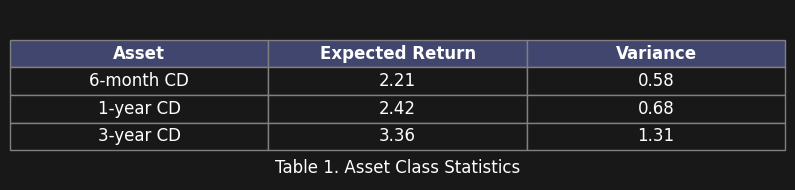

In [2]:
# plot the table of option data
# Sample data preparation
df = assets[['6-month CD', '1-year CD', '3-year CD']]
expected_returns = df.mean()
variances = df.var()

# Create DataFrame with Asset names as a column
statistics_df = pd.DataFrame({
    'Asset': expected_returns.index,  # Add Asset names as a column
    'Expected Return': expected_returns.values,
    'Variance': variances.values
}).round(2)

# Set dark theme styling
plt.style.use("dark_background")
plt.rcParams["figure.facecolor"] = "#181818"
plt.rcParams["axes.facecolor"] = "#181818"
plt.rcParams["axes.edgecolor"] = "#181818"

# Create the table
plt.figure(figsize=(8, 2))  # Wider to accommodate extra column
ax = plt.gca()
ax.axis('off')

# Create the table - note we now include all columns
table = plt.table(
    cellText=statistics_df.values,
    colLabels=statistics_df.columns,  # Includes 'Asset' header
    cellLoc='center',
    loc='center',
    colColours=['#40466e'] * len(statistics_df.columns)  # Uniform header color
)

# Style cells
for (i, j), cell in table.get_celld().items():
    if i == 0:  # Header row
        cell.set_text_props(weight='bold', color='white')
        cell.set_facecolor('#40466e')
    else:
        cell.set_facecolor('#181818')
    cell.set_edgecolor('gray')

# Style the table
table.auto_set_font_size(False)
table.set_fontsize(12)
table.scale(1.2, 1.5)  # Adjust cell size

plt.title('Table 1. Asset Class Statistics', y=-0.01, color='white')
plt.tight_layout()
plt.show()

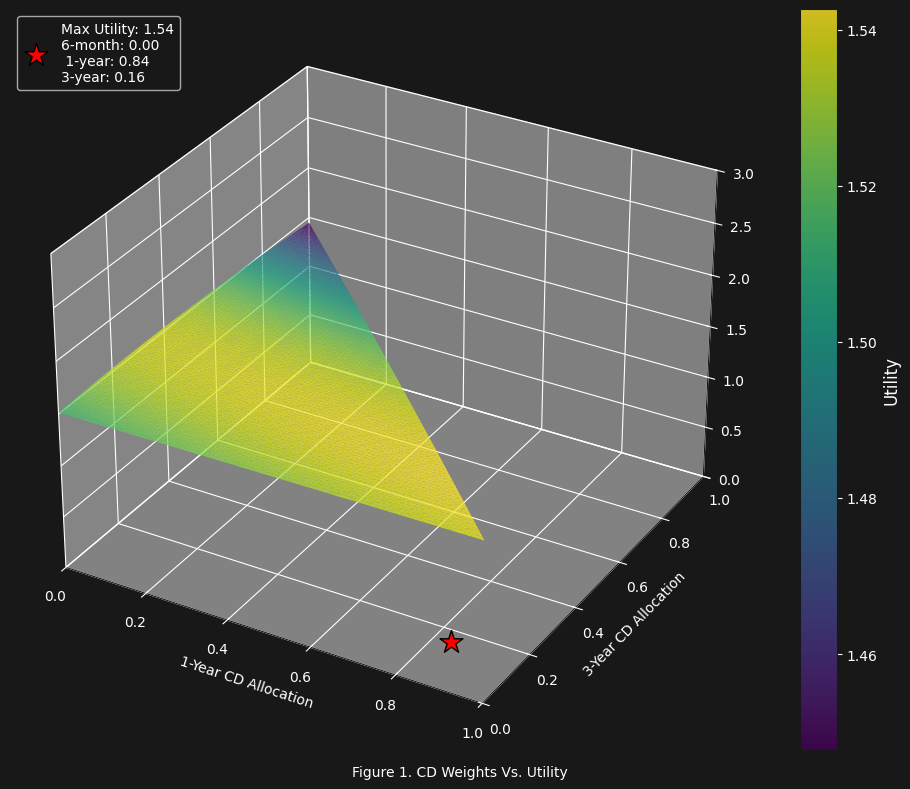

In [3]:
from mpl_toolkits.mplot3d import Axes3D

cov_matrix = df.cov()  # Full covariance matrix

# Maturity terms for each asset (in years)
T = np.array([0.6, 1, 3])  # 6-month=0.6, 1-year=1, 3-year=3

# Utility function (with explicit variance terms and liquidity penalty)
def portfolio_utility(weights, lambda_=2, gamma_=0.2):
    port_return = np.dot(weights, expected_returns)
    
    # Portfolio variance (sum of weighted variances + 2*covariances)
    port_variance = 0
    n_assets = len(weights)
    
    # Individual variance terms
    for i in range(n_assets):
        port_variance += (weights[i] ** 2) * variances.iloc[i] 
    
    # Covariance terms (avoid double-counting)
    for i in range(n_assets):
        for j in range(i+1, n_assets):
            port_variance += 2 * weights[i] * weights[j] * cov_matrix.iloc[i, j]

    # Liquidity penalty 
    liquidity_penalty = gamma_ * np.dot(weights, T)
    
    utility = port_return - 0.5 * lambda_ * port_variance - liquidity_penalty
    return port_return, port_variance, liquidity_penalty, utility

# Generate all valid allocations (10% intervals)
allocations = np.arange(0, 1.01, 0.01)
results = []

for w_stock in allocations:
    for w_bond in allocations:
        w_gold = 1 - w_stock - w_bond
        if w_gold >= 0:  # Only valid combinations
            weights = np.array([w_stock, w_bond, w_gold])
            ret, var, lp, util = portfolio_utility(weights)
            
            results.append({
                '6-month CD weight': w_stock,
                '1-year CD weight': w_bond,
                '3-year CD weight': w_gold,
                'Expected Return': round(ret, 6),
                'Portfolio Variance': round(var, 6),
                'Liquidity Penalty': round(lp, 6),
                'Utility': round(util, 6),
                'Var_6-month': round((weights[0]**2) * variances.iloc[0], 6),
                'Var_1-year': round((weights[1]**2) * variances.iloc[1], 6),
                'Var_3-year': round((weights[2]**2) * variances.iloc[2], 6),
                'Cov_6month_1year': round(2 * weights[0] * weights[1] * cov_matrix.iloc[0,1], 6),
                'Cov_6month_3year': round(2 * weights[0] * weights[2] * cov_matrix.iloc[0,2], 6),
                'Cov_1year_3year': round(2 * weights[1] * weights[2] * cov_matrix.iloc[1,2], 6)
            })

# Convert to DataFrame
results_df = pd.DataFrame(results)
results_df_sorted = results_df.sort_values(by='Utility', ascending=False)

# Find maximum utility point
max_idx = results_df['Utility'].idxmax()
max_point = results_df.loc[max_idx]



# 3D Plot of Utility vs. Stocks/Bonds
fig_count = 1
fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection='3d')

scatter = ax.plot_trisurf(
    results_df['1-year CD weight'],
    results_df['3-year CD weight'],
    results_df['Utility'],
    cmap='viridis',
    linewidth=0.2,
    antialiased=True,
    alpha=0.8
)
ax.set_xlabel('1-Year CD Allocation')
ax.set_ylabel('3-Year CD Allocation')
#ax.set_zlabel('Utility')

# Highlight maximum utility point with a red star
max_marker = ax.scatter(
    max_point['1-year CD weight'],
    max_point['3-year CD weight'],
    c='red',
    marker='*',
    s=300,
    edgecolors='black',
    linewidth=1,
    label=f"Max Utility: {max_point['Utility']:.2f}\n"
            f"6-month: {max_point['6-month CD weight']:.2f}\n "
          f"1-year: {max_point['1-year CD weight']:.2f}\n"
          f"3-year: {max_point['3-year CD weight']:.2f}"
)

# Add color bar
cbar = plt.colorbar(scatter, ax=ax)
cbar.set_label('Utility', fontsize=12)

# Add legend
ax.legend(loc='upper left', bbox_to_anchor=(0, 1), fontsize=10)

# Adjust plot limits
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.set_zlim(0, 3)



# set title
plt.suptitle(
    f"Figure {fig_count}. CD Weights Vs. Utility", y=0.0001, fontsize=10
)
fig_count += 1

# Show plot
plt.tight_layout()
plt.show()

From Figure 1, we can see that the utility of Level 2 reaches maximum ($U=1.54$) when the investment strategy is:

+ 6-month CD: 0%
+ 1-year CD: 84%
+ 3-year CD: 16%

Thus, we demonstrated a complete process — from defining the utility function to deriving the optimal strategy. The utility function can be adjusted to reflect varying risk tolerance, liquidity preferences, and other goal-dependent factors.

## Conclusion ##

By examining the relationships between hierarchy, utility, strategy, and options, we observe that the hierarchy establishes the goal and key factors for the utility function. Calculating utility then enables us to determine the optimal strategy — a weighted combination of different options.

In the next phase, we will define specific utility functions and derive optimal strategies for each level of the wealth-building hierarchy.